In [15]:
!pip install qiskit qiskit-aer matplotlib pylatexenc


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import qiskit
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display

print("Qiskit Version:", qiskit.__version__)
print("Libraries imported successfully!")

Qiskit Version: 2.6.2
Libraries imported successfully!


In [17]:
# Create 3 data qubits
data = QuantumRegister(3, 'data')

# Create 2 ancilla qubits for error detection
ancilla = QuantumRegister(2, 'ancilla')

# Create classical register for syndrome
syn = ClassicalRegister(2, 'syndrome')

# Create classical register for final output
output = ClassicalRegister(3, 'output')

# Create quantum circuit
qec = QuantumCircuit(data, ancilla, syn, output)

# STEP 1: Prepare initial logical state |1>
qec.x(data[0])

# STEP 2: Encode logical |1> into |111>
qec.cx(data[0], data[1])
qec.cx(data[0], data[2])

qec.barrier()

# STEP 3: Introduce bit-flip error on middle qubit
qec.x(data[1])

qec.barrier()

# STEP 4: Syndrome extraction
# First ancilla checks parity between data[0] and data[1]
qec.cx(data[0], ancilla[0])
qec.cx(data[1], ancilla[0])

# Second ancilla checks parity between data[1] and data[2]
qec.cx(data[1], ancilla[1])
qec.cx(data[2], ancilla[1])

qec.barrier()

# STEP 5: Measure syndrome
qec.measure(ancilla[0], syn[0])
qec.measure(ancilla[1], syn[1])

qec.barrier()

# STEP 6: Apply error correction based on syndrome

# Syndrome 01 (decimal 1): error on data[0]
with qec.if_test((syn, 1)):
    qec.x(data[0])

# Syndrome 11 (decimal 3): error on data[1]
with qec.if_test((syn, 3)):
    qec.x(data[1])

# Syndrome 10 (decimal 2): error on data[2]
with qec.if_test((syn, 2)):
    qec.x(data[2])

qec.barrier()

# STEP 7: Measure corrected data qubits
qec.measure(data[0], output[0])
qec.measure(data[1], output[1])
qec.measure(data[2], output[2])

print("Quantum Error Correction Circuit Created Successfully!")

Quantum Error Correction Circuit Created Successfully!


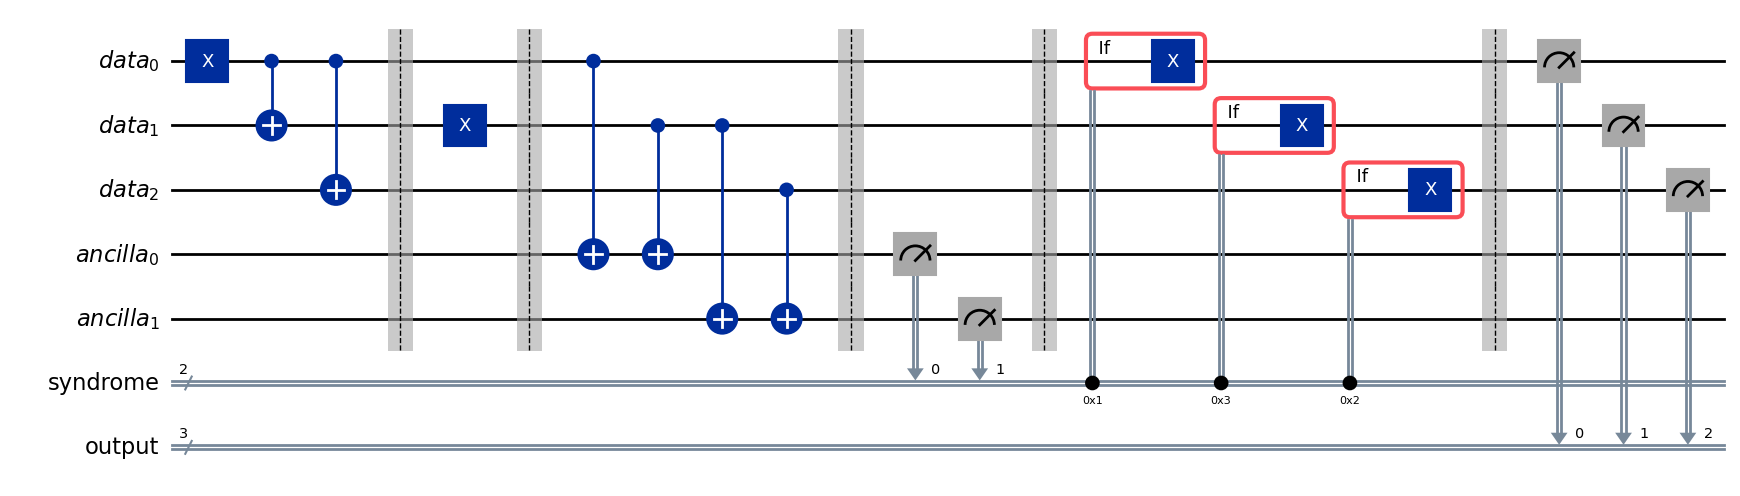

In [18]:
display(qec.draw(output='mpl', fold=-1))

In [19]:
# Create Aer simulator
simulator = AerSimulator()

# Transpile circuit for simulator
compiled_qec = transpile(qec, simulator)

# Execute circuit for 1000 shots
job = simulator.run(compiled_qec, shots=1000)

# Get results
result = job.result()

# Get measurement counts
counts = result.get_counts(compiled_qec)

print("Quantum Error Correction Output")
print("--------------------------------")
print(counts)

Quantum Error Correction Output
--------------------------------
{'111 11': 1000}


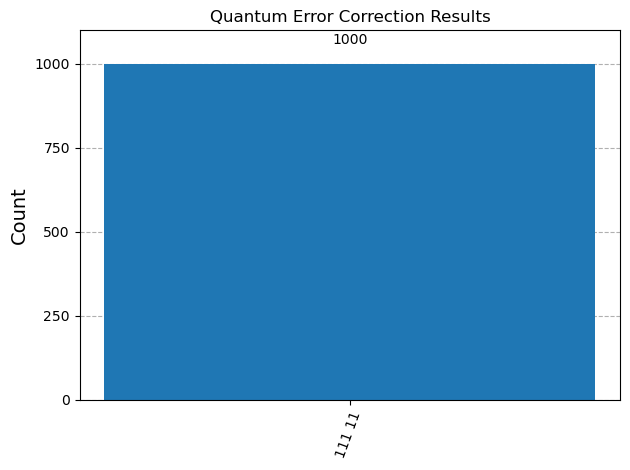

In [20]:
histogram = plot_histogram(
    counts,
    title="Quantum Error Correction Results"
)

display(histogram)
plt.show()

In [21]:
# Create a separate circuit without error correction
data_original = QuantumRegister(3, 'data')
output_original = ClassicalRegister(3, 'output')

original = QuantumCircuit(data_original, output_original)

# Prepare logical state |1>
original.x(data_original[0])

# Encode into |111>
original.cx(data_original[0], data_original[1])
original.cx(data_original[0], data_original[2])

# Introduce bit-flip error on middle qubit
original.x(data_original[1])

# Measure without correction
original.measure(data_original[0], output_original[0])
original.measure(data_original[1], output_original[1])
original.measure(data_original[2], output_original[2])

# Simulate original circuit
compiled_original = transpile(original, simulator)

job_original = simulator.run(compiled_original, shots=1000)

result_original = job_original.result()

original_counts = result_original.get_counts(compiled_original)

print("Output Without Error Correction:")
print(original_counts)

print("\nOutput With Error Correction:")
print(counts)

Output Without Error Correction:
{'101': 1000}

Output With Error Correction:
{'111 11': 1000}


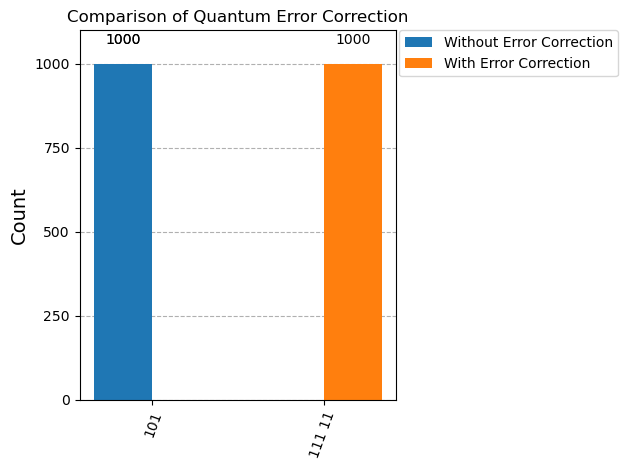

In [22]:
comparison = plot_histogram(
    [original_counts, counts],
    legend=['Without Error Correction', 'With Error Correction'],
    title='Comparison of Quantum Error Correction'
)

display(comparison)
plt.show()

In [23]:
# Extract corrected data bits from measurement results
corrected_output = max(
    counts,
    key=counts.get
).split()[0]

print("Most frequent corrected output:", corrected_output)

if corrected_output == '111':
    print("\nERROR CORRECTION SUCCESSFUL!")
    print("The original logical state |1> was recovered.")
else:
    print("\nERROR CORRECTION FAILED!")
    print("Check the circuit and correction conditions.")

Most frequent corrected output: 111

ERROR CORRECTION SUCCESSFUL!
The original logical state |1> was recovered.
